# Metric Stat Analysis – PPP Radar Evaluation (Alignment Ratio)

Loads pre-exported HDF5 evaluation files (`rank00.h5` – `rank03.h5`) and evaluates
spatial alignment between `pred_lambda` and `gt_support` via the **alignment ratio**.

## Primary metric

$$s = \frac{\bar{\lambda}_\mathrm{pts}}{\bar{\lambda}} = \frac{\frac{1}{|P|}\sum_{i \in P} \lambda_i}{\frac{1}{D}\sum_i \lambda_i}$$

**Interpretation**: how many times higher the mean heatmap intensity is at point locations vs the global average.

**Key properties**:
- $s > 1$: points are at **above-average** heatmap intensity → good alignment
- $s = 1$: points are at the **global mean** → no alignment signal
- $s < 1$: points are **below average** → misaligned
- Independent of the number of points and scale-invariant in $\lambda$.
- **Thinning null gives $E[s] = 1$ by construction.**

Each h5 file organises samples as:
```
sample_XXXXXX/
    img          (H, W, 3)  uint8
    pred_lambda  (H, W)     float32   ← predicted PPP intensity λ(x)
    gt_support   (H, W)     float32   ← binary point support {0, 1}
```


## 1 · Import Required Libraries

In [85]:
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation

plt.rcParams["figure.figsize"] = (18, 5)
plt.rcParams["image.cmap"] = "hot"

## 2 · Configuration & Path Setup

In [86]:

# ---------------------------------------------------------------------------
# Paths – one entry per model run
# ---------------------------------------------------------------------------

H5_DIRS = {
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608_LR_load_model40000": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13606074": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test"
    ),
}


# Select which model to analyse for the browser / per-sample cells
# ACTIVE_MODEL = "test_gen_data_meric_13600264"
ACTIVE_MODEL = "test_gen_data_meric_13600264"

H5_DIR = H5_DIRS[ACTIVE_MODEL]
assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

# ---------------------------------------------------------------------------
# Display parameters
# ---------------------------------------------------------------------------

# Radius (pixels) used to dilate each GT point for visibility.
# Increase to make GT dots larger in the output image.
GT_DILATION_RADIUS = 1

# ---------------------------------------------------------------------------
# Collect h5 files for the active model (browser / per-sample cells)
# ---------------------------------------------------------------------------

h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"\nFound {len(h5_files)} h5 file(s):")
for p in h5_files:
    print(" ", p)

print(f"\nAll models registered: {list(H5_DIRS.keys())}")
print(f"GT_DILATION_RADIUS = {GT_DILATION_RADIUS}  (display only)")


Active model : test_gen_data_meric_13600264
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test

Found 4 h5 file(s):
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank03.h5

All models registered: ['test_gen_data_meric_13600264', 'test_gen_data_meric_1500_13603608_LR_load_model40000', 'test_gen_data_meric_1500_13606074']
GT_DILATION_RADIUS = 1  (display only)


## 3 · H5 Helper – List & Load Samples

In [87]:
def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) tuples across all rank files,
    sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from an h5 file.

    Returns a dict with:
      img          – (H, W, 3) uint8
      pred_lambda  – (H, W) float32   [lambda(x), i.e. predicted intensity]
      gt_support   – (H, W) float32   [binary point support {0,1}]
      ppp          – derived diagnostics dict
    """
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]           # (H, W, 3) uint8
        pred_lambda = grp["pred_lambda"][:]   # (H, W)    float32
        gt_support  = grp["gt_support"][:]    # (H, W)    float32

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count       = int(gt_support.sum())

    return {
        "img":         img,
        "pred_lambda": pred_lambda,
        "gt_support":  gt_support,
        "ppp": {
            "H":              H,
            "W":              W,
            "img_area":       H * W,
            "expected_count": expected_count,
            "gt_count":       gt_count,
            "count_error":    expected_count - gt_count,
        },
        "meta": {
            "h5_file":    os.path.basename(h5_path),
            "sample_key": sample_key,
        },
    }


# Build global sample index
all_samples = list_h5_samples(h5_files)
print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(f"  {os.path.basename(entry[0])} / {entry[1]}")

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


## 4 · PPP Sampling Methods

In [88]:
def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) per pixel (mass per pixel, non-negative).
    pixel_area : float
        Kept for API compatibility, not used.
    rng : np.random.Generator

    Returns
    -------
    points_xy  : (N, 2) array  – accepted points in image coords (x, y)
    N          : int
    lambda_max : float
    N_prop     : int           – number of proposals before thinning
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",
    rng: np.random.Generator | None = None,
):
    """
    Block/Bernoulli approximation of a PPP.

    For each block A:
        Λ_A = sum_A λ * pixel_area
        Activate with p_A = 1 - exp(-Λ_A)
    If active, place exactly one point in A.

    Parameters
    ----------
    lambda_grid : (H, W) array  – intensity mass per pixel
    block_size  : int           – side length of each block in pixels
    pixel_area  : float         – set to 1.0 when lambda_grid is already mass per pixel
    placement   : "weighted" | "uniform"

    Returns
    -------
    points_xy : (N, 2) array
    stats     : dict
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    if lam.ndim != 2:
        raise ValueError("lambda_grid must be 2D.")
    if not np.all(np.isfinite(lam)):
        raise ValueError("lambda_grid contains NaN/Inf.")
    if np.any(lam < 0):
        raise ValueError("lambda_grid contains negative values.")
    if placement not in {"weighted", "uniform"}:
        raise ValueError("placement must be 'weighted' or 'uniform'")

    bs = int(block_size)
    H, W = lam.shape
    nby = (H + bs - 1) // bs
    nbx = (W + bs - 1) // bs
    num_blocks = nby * nbx

    Hp, Wp = nby * bs, nbx * bs
    if Hp != H or Wp != W:
        lam_pad = np.zeros((Hp, Wp), dtype=np.float64)
        lam_pad[:H, :W] = lam
    else:
        lam_pad = lam

    lam_blocks = lam_pad.reshape(nby, bs, nbx, bs).transpose(0, 2, 1, 3)
    block_sums = lam_blocks.sum(axis=(2, 3)) * pixel_area  # (nby, nbx)

    p_active = 1.0 - np.exp(-block_sums)
    expected_blocks_active = float(p_active.sum())

    active_mask = rng.random(size=(nby, nbx)) < p_active
    active_by, active_bx = np.nonzero(active_mask)
    num_active = active_by.size

    if num_active == 0:
        return np.zeros((0, 2), dtype=np.float64), dict(
            block_size=bs, placement=placement,
            num_blocks=num_blocks, num_active_blocks=0,
            expected_active_blocks=expected_blocks_active, num_points=0,
        )

    points_xy = np.empty((num_active, 2), dtype=np.float64)
    x0s = active_bx * bs
    y0s = active_by * bs
    wBs = np.minimum(bs, W - x0s)
    hBs = np.minimum(bs, H - y0s)

    if placement == "uniform":
        points_xy[:, 0] = x0s + rng.random(num_active) * wBs
        points_xy[:, 1] = y0s + rng.random(num_active) * hBs
    else:
        for i, (by, bx, x0, y0, wB, hB) in enumerate(
            zip(active_by, active_bx, x0s, y0s, wBs, hBs)
        ):
            block = lam[y0:y0 + hB, x0:x0 + wB]
            s = block.sum()
            if s <= 0:
                points_xy[i, 0] = x0 + rng.random() * wB
                points_xy[i, 1] = y0 + rng.random() * hB
                continue
            probs = block.ravel() / s
            idx = rng.choice(probs.size, p=probs)
            py, px = divmod(idx, wB)
            points_xy[i, 0] = x0 + px + rng.random()
            points_xy[i, 1] = y0 + py + rng.random()

    return points_xy, dict(
        block_size=bs, placement=placement,
        num_blocks=num_blocks, num_active_blocks=int(num_active),
        expected_active_blocks=expected_blocks_active, num_points=int(num_active),
    )

print("Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli")


Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli


## 4 · Load & Display First Sample: Image, Lambda, GT

Sample : rank00.h5  /  sample_000000
Shape  : img=(544, 1792, 3)  pred_lambda=(544, 1792) _gt_support=(544, 1792)
PPP    : E[N]=106.85  GT=67  err=+39.85


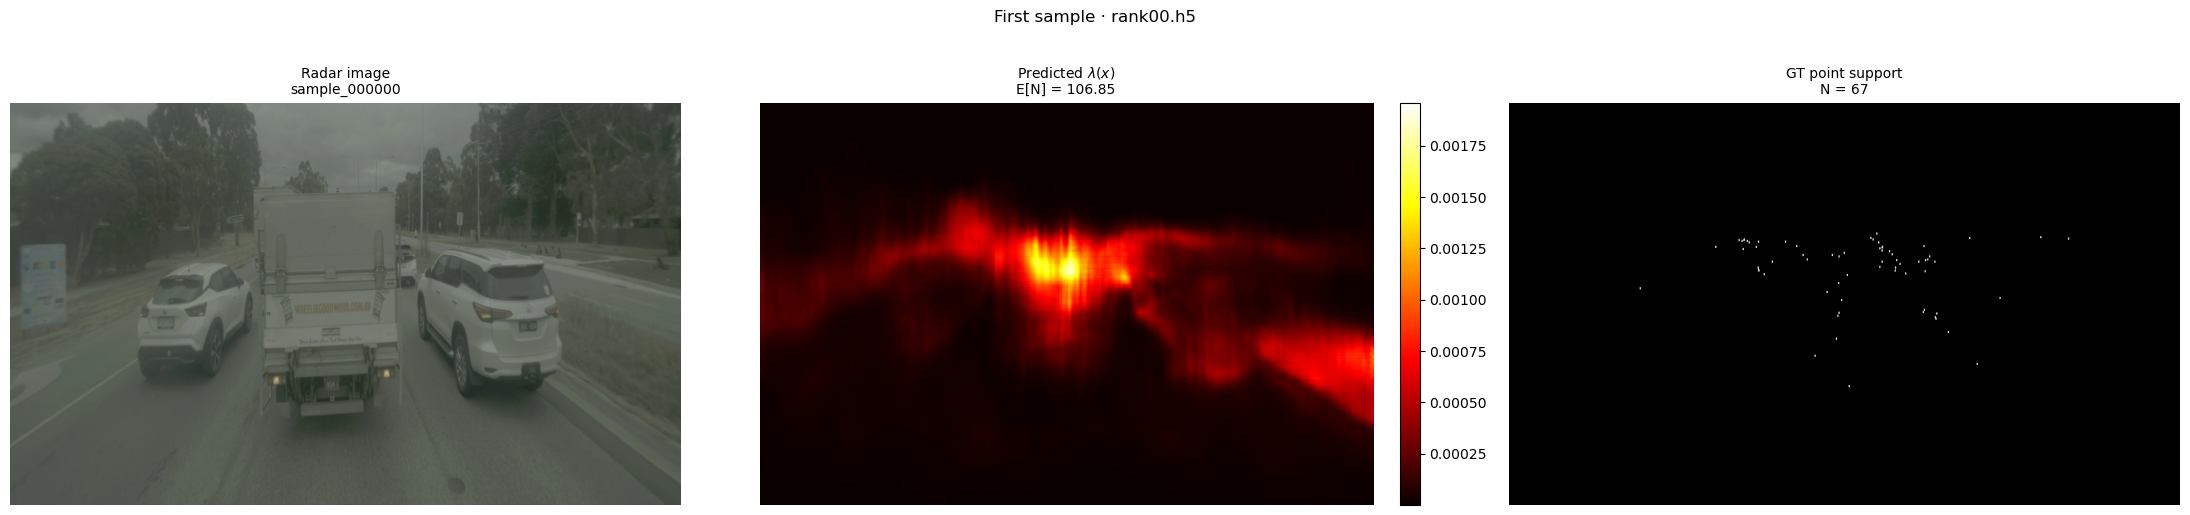

In [89]:
# Load first sample
h5_path_0, key_0 = all_samples[0]
sample = load_h5_sample(h5_path_0, key_0)

img         = sample["img"]
pred_lambda = sample["pred_lambda"]
gt_support  = sample["gt_support"]   # original – untouched
ppp         = sample["ppp"]
meta        = sample["meta"]

print(f"Sample : {meta['h5_file']}  /  {meta['sample_key']}")
print(f"Shape  : img={img.shape}  pred_lambda={pred_lambda.shape} _gt_support={gt_support.shape}")
print(f"PPP    : E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}  err={ppp['count_error']:+.2f}")

# GT point coordinates (row=y, col=x)
gt_ys, gt_xs = np.where(gt_support > 0)

# --- Side-by-side plot ---
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

ax = axes[0]
ax.imshow(img, aspect="auto")
ax.set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
ax.axis("off")

ax = axes[1]
im = ax.imshow(pred_lambda, cmap="hot", aspect="auto")
ax.set_title(
    r"Predicted $\lambda(x)$"
    f"\nE[N] = {ppp['expected_count']:.2f}",
    fontsize=10,
)
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax = axes[2]
_struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
_gt_vis = binary_dilation(gt_support > 0, structure=_struct)
gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
gt_rgb[_gt_vis] = 255
ax.imshow(gt_rgb, aspect="auto")
ax.set_title(
    f"GT point support\nN = {ppp['gt_count']}",
    fontsize=10,
)
ax.axis("off")

plt.suptitle(f"First sample · {meta['h5_file']}", fontsize=12, y=1.02)


plt.tight_layout()
plt.show()

In [90]:
# Pick 10 random samples from all_samples and report pred_lambda stats
assert len(all_samples) > 0, "all_samples is empty."

rng = np.random.default_rng(42)
k = min(10, len(all_samples))
picked_idx = rng.choice(len(all_samples), size=k, replace=False)

heatmap_stats = []
for i in picked_idx:
    h5_path, sample_key = all_samples[i]
    s = load_h5_sample(h5_path, sample_key)
    lam = s["pred_lambda"].astype(np.float64)

    heatmap_stats.append({
        "h5_file": os.path.basename(h5_path),
        "sample_key": sample_key,
        "max": float(lam.max()),
        "min": float(lam.min()),
        "mean": float(lam.mean()),
        "variance": float(lam.var()),
    })

print(f"Randomly selected {k} sample(s):\n")
for row in heatmap_stats:
    print(
        f"{row['h5_file']} / {row['sample_key']}  "
        f"max={row['max']:.6f}  min={row['min']:.6f}  "
        f"mean={row['mean']:.6f}  var={row['variance']:.6f}"
    )

Randomly selected 10 sample(s):

rank00.h5 / sample_000042  max=0.014833  min=0.000000  mean=0.000293  var=0.000001
rank03.h5 / sample_000005  max=0.041295  min=0.000000  mean=0.000203  var=0.000002
rank00.h5 / sample_000043  max=0.001602  min=0.000005  mean=0.000187  var=0.000000
rank02.h5 / sample_000072  max=0.004771  min=0.000005  mean=0.000232  var=0.000000
rank01.h5 / sample_000091  max=0.074664  min=0.000000  mean=0.000193  var=0.000002
rank01.h5 / sample_000089  max=0.090229  min=0.000000  mean=0.000224  var=0.000002
rank02.h5 / sample_000097  max=0.020466  min=0.000000  mean=0.000179  var=0.000001
rank00.h5 / sample_000047  max=0.001333  min=0.000003  mean=0.000127  var=0.000000
rank00.h5 / sample_000100  max=0.004594  min=0.000000  mean=0.000099  var=0.000000
rank03.h5 / sample_000050  max=0.024412  min=0.000000  mean=0.000302  var=0.000001


## 5 · Interactive Sample Browser

Use the slider to step through samples. Click **"Add to selection"** to mark the current sample. The selected keys are collected in `selected_samples` (printed in the cell below).

In [91]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# ── persistent selection list ────────────────────────────────────────────────
selected_samples = []   # list of (h5_file, sample_key)

# ── widgets ──────────────────────────────────────────────────────────────────
n = len(all_samples)

slider = widgets.IntSlider(
    value=0, min=0, max=n - 1, step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="600px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆  Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

lbl_status = widgets.Label(value=f"0 / {n} selected")

plot_out   = widgets.Output()
select_out = widgets.Output()


def _update_btn_label(idx):
    """Reflect whether the current sample is already in the selection."""
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)
    btn_add.value       = entry in selected_samples
    btn_add.description = "★  In selection" if btn_add.value else "☆  Add to selection"
    btn_add.button_style = "success" if btn_add.value else ""


def _render(idx):
    h5_path, key = all_samples[idx]
    sample = load_h5_sample(h5_path, key)

    img         = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support  = sample["gt_support"]
    ppp         = sample["ppp"]
    meta        = sample["meta"]

    gt_ys, gt_xs = np.where(gt_support > 0)

    with plot_out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(22, 5))

        axes[0].imshow(img, aspect="auto")
        axes[0].set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
        axes[0].axis("off")

        im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
        axes[1].set_title(
            r"Predicted $\lambda(x)$" + f"\nE[N] = {ppp['expected_count']:.2f}",
            fontsize=10,
        )
        axes[1].axis("off")
        plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

        _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
        _gt_vis = binary_dilation(gt_support > 0, structure=_struct)
        _gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
        _gt_rgb[_gt_vis] = 255
        axes[2].imshow(_gt_rgb, aspect="auto")
        axes[2].set_title(
            f"GT support\nN = {ppp['gt_count']}",
            fontsize=10,
        )
        axes[2].axis("off")

        plt.suptitle(
            f"[{idx + 1}/{n}]  {meta['h5_file']}  ·  {meta['sample_key']}"
            f"   |   E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}"
            f"  err={ppp['count_error']:+.2f}",
            fontsize=11, y=1.02,
        )
        plt.tight_layout()
        plt.show()


def _refresh_selection_output():
    with select_out:
        clear_output(wait=True)
        if selected_samples:
            print(f"Selected ({len(selected_samples)}):")
            for h5f, k in selected_samples:
                print(f"  {h5f}  /  {k}")
        else:
            print("No samples selected yet.")


def on_slider_change(change):
    _update_btn_label(change["new"])
    _render(change["new"])


def on_toggle_change(change):
    idx = slider.value
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)

    if change["new"]:                          # toggled ON → add
        if entry not in selected_samples:
            selected_samples.append(entry)
        btn_add.description  = "★  In selection"
        btn_add.button_style = "success"
    else:                                      # toggled OFF → remove
        if entry in selected_samples:
            selected_samples.remove(entry)
        btn_add.description  = "☆  Add to selection"
        btn_add.button_style = ""

    lbl_status.value = f"{len(selected_samples)} / {n} selected"
    _refresh_selection_output()


slider.observe(on_slider_change, names="value")
btn_add.observe(on_toggle_change, names="value")

# ── initial render ────────────────────────────────────────────────────────────
_update_btn_label(0)
_render(0)
_refresh_selection_output()

# ── layout ────────────────────────────────────────────────────────────────────
controls = widgets.HBox([slider, btn_add, lbl_status])

display(widgets.VBox([controls, plot_out, select_out]))
# ── layout ────────────────────────────────────────────────────────────────────controls = widgets.HBox([slider, btn_add, lbl_status])display(widgets.VBox([controls, plot_out, select_out]))


In [92]:
# ── Print final selection (run this cell after browsing) ─────────────────────
print(f"selected_samples = {selected_samples!r}")


selected_samples = [('rank00.h5', 'sample_000000')]


## Analysis: Per-sample evaluation (Alignment Ratio)

For every sample in `selected_samples`, produces one combined figure with 5 panels:

1. **Image + GT** – ground-truth point overlay  
2. **Image + λ heatmap** – predicted intensity overlaid on the radar image  
3. **Image + Thinning sample** – one PPP draw via thinning  
4. **Fake GT** – Gaussian cluster where the model predicts nothing (misalignment reference)
5. **Alignment ratio distributions** – $s = \bar{\lambda}_\mathrm{pts} / \bar{\lambda}$ for N draws per method.  
   Real GT and fake GT shown as reference lines.  **$s > 1$ = above-average alignment. Thinning null ≈ 1.**

> **Metric**: ratio of mean heatmap intensity at point locations to global mean.  
> Count-independent, scale-invariant, and has a natural null of 1.


In [93]:
# Max heatmap (pred_lambda) value across selected_samples
assert selected_samples, "selected_samples is empty."

global_max = -np.inf
global_arg = None

for h5_file, sample_key in selected_samples:
    h5_path = next(
        p for (p, k) in all_samples
        if os.path.basename(p) == h5_file and k == sample_key
    )
    s = load_h5_sample(h5_path, sample_key)
    m = float(np.max(s["pred_lambda"]))
    if m > global_max:
        global_max = m
        global_arg = (h5_file, sample_key)

print(f"Max heatmap value (pred_lambda): {global_max:.6f}")
print(f"Found in: {global_arg[0]} / {global_arg[1]}")

Max heatmap value (pred_lambda): 0.001961
Found in: rank00.h5 / sample_000000


In [ ]:

# ── Low-level helpers ────────────────────────────────────────────────────────
from scipy import stats as scipy_stats

EPS = 1e-8  # global numerical-stability constant


def points_to_binary_grid(points_xy: np.ndarray, H: int, W: int) -> np.ndarray:
    """Convert a point cloud to a binary occupancy grid (H, W) with values {0, 1}."""
    grid = np.zeros((H, W), dtype=np.float64)
    if points_xy.shape[0] > 0:
        xi = np.clip(points_xy[:, 0].astype(int), 0, W - 1)
        yi = np.clip(points_xy[:, 1].astype(int), 0, H - 1)
        grid[yi, xi] = 1.0
    return grid


def heatmap_mass_score(
    x_gt: np.ndarray,
    lam: np.ndarray,
    eps: float = EPS,
) -> float:
    """
    Ratio of mean heatmap value at point locations to global mean heatmap value.

        score = mean_{i in pts}(lambda_i) / mean_i(lambda_i)
              = (sum_{i in pts} lambda_i / |pts|) / (sum_i lambda_i / D)

    Properties
    ----------
    - Independent of the number of points (both num and denom divide by count).
    - Scale-invariant in lambda (ratio cancels the overall scale).
    - score > 1: points are in above-average heatmap regions  (good alignment).
    - score = 1: points are at the global average             (no alignment signal).
    - score < 1: points are in below-average heatmap regions  (misaligned).
    - Thinning null has E[score] = 1 by construction.

    Parameters
    ----------
    x_gt : (H, W) or (D,) — binary occupancy {0, 1}
    lam  : (H, W) or (D,) — predicted intensity (non-negative)

    Returns
    -------
    float >= 0, or nan if point cloud is empty or heatmap is all-zero.
    """
    x = np.asarray(x_gt, dtype=np.float64).ravel()
    l = np.asarray(lam,  dtype=np.float64).ravel()
    if x.shape != l.shape:
        raise ValueError(f"Shape mismatch: x_gt {x_gt.shape} vs lam {lam.shape}")
    n_pts = float(x.sum())
    if n_pts < eps:
        return np.nan
    global_mean = float(l.mean())
    if global_mean < eps:
        return np.nan
    return float(np.dot(x, l) / n_pts / global_mean)


def project_onto_heatmap(
    x_gt: np.ndarray,
    lam: np.ndarray,
    eps: float = EPS,
) -> dict:
    """
    Auxiliary: orthogonal projection of x_gt onto span{lam} (used in visualize_projection).

    Returns dict with: c_star, cos_sim, norm_residual_sq, residual_norm,
                       residual_sq, norm_l_sq, norm_x_sq, degenerate.
    Primary metric for analysis is heatmap_mass_score(), not this function.
    """
    x = np.asarray(x_gt, dtype=np.float64).ravel()
    l = np.asarray(lam,  dtype=np.float64).ravel()
    if x.shape != l.shape:
        raise ValueError(f"Shape mismatch: x_gt {x_gt.shape} vs lam {lam.shape}")

    norm_l_sq = float(np.dot(l, l))
    norm_x_sq = float(np.dot(x, x))
    dot_xl    = float(np.dot(x, l))

    if norm_l_sq < eps:
        return dict(c_star=0.0, residual_norm=float(np.sqrt(norm_x_sq)),
                    cos_sim=np.nan, norm_residual_sq=np.nan,
                    residual_sq=norm_x_sq, norm_l_sq=norm_l_sq,
                    norm_x_sq=norm_x_sq, degenerate=True)

    c_star        = dot_xl / norm_l_sq
    residual      = x - c_star * l
    residual_sq   = float(np.dot(residual, residual))
    residual_norm = float(np.sqrt(residual_sq))

    if norm_x_sq < eps:
        return dict(c_star=float(c_star), residual_norm=residual_norm,
                    cos_sim=np.nan, norm_residual_sq=np.nan,
                    residual_sq=residual_sq, norm_l_sq=norm_l_sq,
                    norm_x_sq=norm_x_sq, degenerate=True)

    cos_sim          = float(np.clip(dot_xl / (np.sqrt(norm_x_sq) * np.sqrt(norm_l_sq)), -1.0, 1.0))
    norm_residual_sq = float(np.clip(residual_sq / norm_x_sq, 0.0, 1.0))

    return dict(c_star=float(c_star), residual_norm=residual_norm,
                cos_sim=cos_sim, norm_residual_sq=norm_residual_sq,
                residual_sq=residual_sq, norm_l_sq=norm_l_sq,
                norm_x_sq=norm_x_sq, degenerate=False)


def _projection_scalar(x_gt: np.ndarray, lam: np.ndarray) -> float:
    """
    Return heatmap_mass_score = mean_lambda(pts) / mean_lambda(global)  (>1 = good).
    NaN (empty point cloud or zero heatmap) → 0.0 as worst-case fallback.
    """
    v = heatmap_mass_score(x_gt, lam)
    return 0.0 if np.isnan(v) else v


def empirical_null_zscores(
    r_gt: np.ndarray,
    thin_draws: list[np.ndarray],
    bb_draws: list[np.ndarray],
    eps: float = EPS,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Empirically-normalised per-sample z-scores using thinning draws as null.
    μ_s, σ_s from K thinning draws; z = (r − μ_s) / σ_s.
    LOO self-check for thinning.  σ_s < eps → z=0.
    """
    S = len(r_gt)
    z_gt_s   = np.full(S, np.nan)
    z_thin_s = np.full(S, np.nan)
    z_bb_s   = np.full(S, np.nan)
    sigma_s  = np.full(S, np.nan)

    for i in range(S):
        draws = thin_draws[i]
        K     = len(draws)
        mu    = draws.mean()
        sig   = draws.std(ddof=1)
        sigma_s[i] = sig

        if sig < eps:
            z_gt_s[i] = z_thin_s[i] = z_bb_s[i] = 0.0
            continue

        z_gt_s[i] = (r_gt[i]            - mu) / sig
        z_bb_s[i] = (bb_draws[i].mean() - mu) / sig

        loo_z = np.empty(K)
        for k in range(K):
            rest     = np.delete(draws, k)
            mu_loo   = rest.mean()
            sig_loo  = rest.std(ddof=1)
            loo_z[k] = (draws[k] - mu_loo) / sig_loo if sig_loo > eps else 0.0
        z_thin_s[i] = loo_z.mean()

    return z_gt_s, z_thin_s, z_bb_s, sigma_s


def calibration_tests(z_s: np.ndarray, label: str, verbose: bool = True) -> dict:
    """Bias (t-test on mean z) + Dispersion (Σz² ~ χ²(S)) tests."""
    z_s = z_s[np.isfinite(z_s)]
    S   = len(z_s)
    if S < 2:
        if verbose: print(f"\n  {label}  (S={S}) — too few samples")
        return dict(t_stat=np.nan, p_bias=np.nan, chi2_sum=np.nan, p_disp=np.nan)
    t_stat, p_bias = scipy_stats.ttest_1samp(z_s, popmean=0.0)
    chi2_sum       = float(np.dot(z_s, z_s))
    p_disp         = float(scipy_stats.chi2.sf(chi2_sum, df=S))
    if verbose:
        b_flag = "  ***" if p_bias < 0.05 else ""
        d_flag = "  ***" if p_disp < 0.05 else ""
        print(f"\n  {label}  (S={S})")
        print(f"    z_s  mean={z_s.mean():+.3f}  SD={z_s.std():.3f}  "
              f"min={z_s.min():+.2f}  max={z_s.max():+.2f}")
        print(f"    Bias test       t={t_stat:+.2f}  p={_fmt_p(p_bias)}{b_flag}")
        print(f"    Dispersion test Σz²={chi2_sum:.1f} (df={S})  p={_fmt_p(p_disp)}{d_flag}")
    return dict(t_stat=t_stat, p_bias=p_bias, chi2_sum=chi2_sum, p_disp=p_disp)


def _fmt_p(p: float) -> str:
    if np.isnan(p):  return "nan"
    if p <= 0.0:     return "<1e-300"
    if p >= 1.0:     return ">1-1e-15"
    if p < 0.001:    return f"{p:.2e}"
    if p > 0.999:    return f"{p:.2e}"
    return f"{p:.3f}"


print("Helpers loaded.")
print("  Primary metric : heatmap_mass_score(x_gt, lam)")
print("                   = mean_λ(pts) / mean_λ(all)  (ratio; >1 = above-average alignment)")
print("  Thinning null has E[score] = 1 by construction.")
print("  _projection_scalar wraps heatmap_mass_score for loops.")
print("  project_onto_heatmap kept for visualize_projection (auxiliary).")


Helpers loaded.
  Primary metric : heatmap_mass_score(x_gt, lam)
                   = sum_{i in pts} λ_i / |pts|  (mean λ at point locs, higher = better)
  _projection_scalar wraps heatmap_mass_score for loops.
  project_onto_heatmap kept for visualize_projection (auxiliary).


/tmp/ipykernel_3712/1417211669.py:145: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(_bp_data, labels=_bp_labels, patch_artist=True,


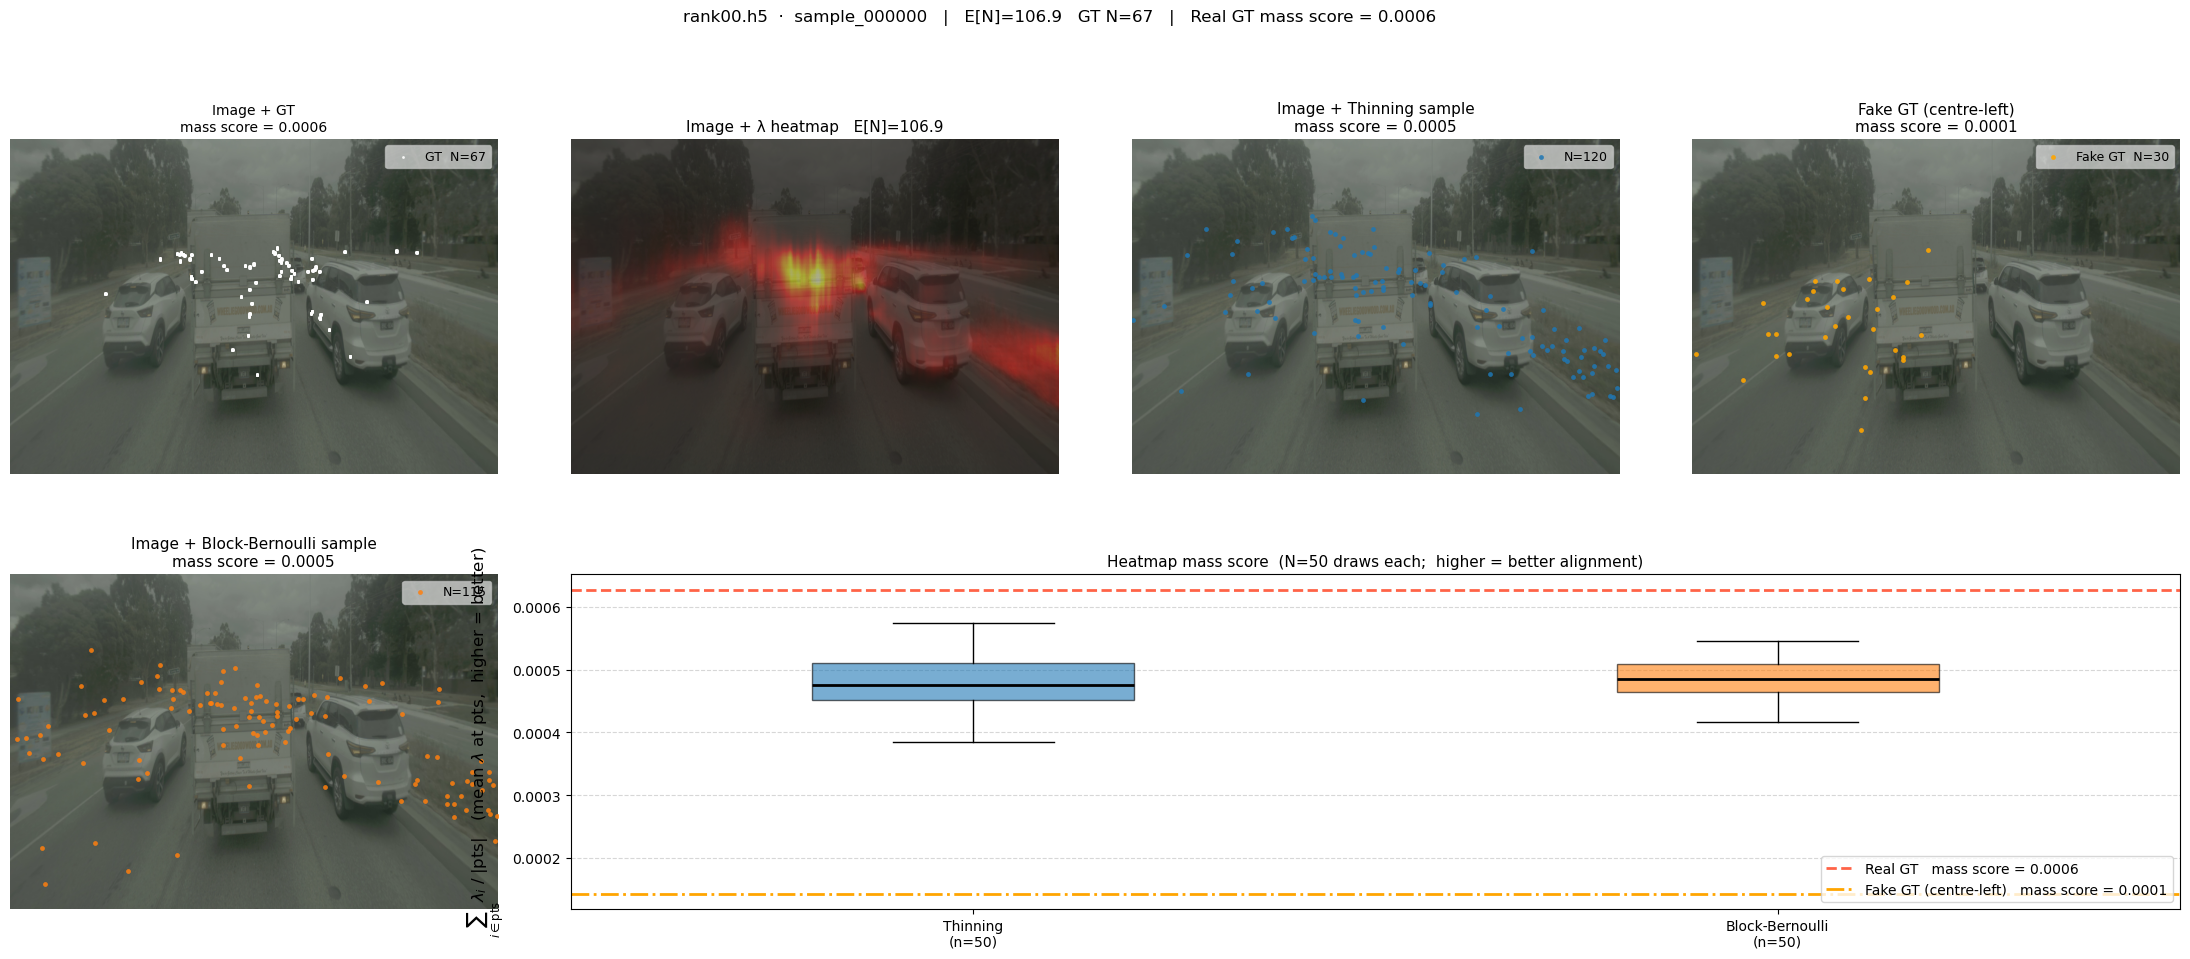

In [ ]:

assert selected_samples, "No samples selected – browse and add at least one above."

from matplotlib.gridspec import GridSpec

DOT_SIZE    = 12
GT_DOT_SIZE = 4
_COLORS     = plt.cm.tab10.colors
N_EVAL      = 50   # draws per method for the box plot
N_FAKE      = 30   # fake GT points (Gaussian cluster)

for _idx, (_h5_file, _key) in enumerate(selected_samples):

    # ── Load sample ──────────────────────────────────────────────────────────
    _h5_path = next(
        p for (p, k) in all_samples
        if os.path.basename(p) == _h5_file and k == _key
    )
    _s           = load_h5_sample(_h5_path, _key)
    _img         = _s["img"]
    _pred_lambda = _s["pred_lambda"]
    _gt_support  = _s["gt_support"]
    _ppp         = _s["ppp"]
    H_img, W_img = _pred_lambda.shape

    # ── Primary metric: alignment ratio ──────────────────────────────────────
    # score = mean_lambda(pts) / mean_lambda(all)
    # Thinning null gives E[score] = 1 by construction.
    # score > 1 = above-average alignment.
    _score_gt = heatmap_mass_score(_gt_support, _pred_lambda)

    # ── Draw one representative sample per method (for display) ──────────────
    _pts_thin_disp, *_ = sample_ppp_by_thinning(
        _pred_lambda, rng=np.random.default_rng(7)
    )
    _pts_bb_disp, _bb_stats_disp = sample_points_block_bernoulli(
        _pred_lambda, block_size=8, placement="weighted",
        rng=np.random.default_rng(7)
    )

    # ── Draw N_EVAL samples per method → collect score distributions ──────────
    _scores_thin = []
    _scores_bb   = []
    for _seed in range(N_EVAL):
        _rng = np.random.default_rng(_seed)
        _pts, *_ = sample_ppp_by_thinning(_pred_lambda, rng=_rng)
        _g = points_to_binary_grid(_pts, H_img, W_img)
        _scores_thin.append(_projection_scalar(_g, _pred_lambda))

        _rng2 = np.random.default_rng(_seed + 10_000)
        _pts2, _ = sample_points_block_bernoulli(
            _pred_lambda, block_size=8, placement="weighted", rng=_rng2
        )
        _g2 = points_to_binary_grid(_pts2, H_img, W_img)
        _scores_bb.append(_projection_scalar(_g2, _pred_lambda))

    # ── Fake "wrong" GT: N_FAKE pts in a Gaussian cluster ────────────────────
    _frng    = np.random.default_rng(42)
    _cx, _cy = W_img * 0.30, H_img * 0.55
    _sx, _sy = W_img * 0.15, H_img * 0.15
    _fake_xs = np.clip(_frng.normal(_cx, _sx, size=N_FAKE), 0, W_img - 1).astype(int)
    _fake_ys = np.clip(_frng.normal(_cy, _sy, size=N_FAKE), 0, H_img - 1).astype(int)
    _fake_gt_grid = points_to_binary_grid(
        np.stack([_fake_xs, _fake_ys], axis=1), H_img, W_img
    )
    _score_fake = heatmap_mass_score(_fake_gt_grid, _pred_lambda)

    # ── Shared helpers ───────────────────────────────────────────────────────
    _ext    = [0, W_img, H_img, 0]
    _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), bool)
    _gt_ys, _gt_xs = np.where(binary_dilation(_gt_support > 0, structure=_struct))

    # ── Figure layout: 2×4 ───────────────────────────────────────────────────
    fig = plt.figure(figsize=(28, 10))
    gs  = GridSpec(2, 4, figure=fig, hspace=0.3, wspace=0.15)
    ax_gt_p   = fig.add_subplot(gs[0, 0])
    ax_lam_p  = fig.add_subplot(gs[0, 1])
    ax_thin_p = fig.add_subplot(gs[0, 2])
    ax_fake_p = fig.add_subplot(gs[0, 3])
    ax_bb_p   = fig.add_subplot(gs[1, 0])
    ax_box    = fig.add_subplot(gs[1, 1:])

    # Panel 0 – Image + GT
    ax_gt_p.imshow(_img, aspect="auto", extent=_ext)
    if _gt_ys.size > 0:
        ax_gt_p.scatter(_gt_xs, _gt_ys, s=GT_DOT_SIZE, c="white",
                        linewidths=0, alpha=0.9, label=f"GT  N={_ppp['gt_count']}")
    ax_gt_p.legend(loc="upper right", fontsize=9, framealpha=0.6)
    ax_gt_p.axis("off")
    ax_gt_p.set_title(
        f"Image + GT\nalignment ratio = {_score_gt:.4f}",
        fontsize=10,
    )

    # Panel 1 – Image + λ heatmap
    ax_lam_p.imshow(_img, aspect="auto", extent=_ext)
    ax_lam_p.imshow(_pred_lambda, cmap="hot", aspect="auto", extent=_ext, alpha=0.45)
    ax_lam_p.axis("off")
    ax_lam_p.set_title(f"Image + λ heatmap   E[N]={_ppp['expected_count']:.1f}", fontsize=11)

    # Panel 2 – Image + Thinning sample
    _score_thin_disp = _projection_scalar(
        points_to_binary_grid(_pts_thin_disp, H_img, W_img), _pred_lambda
    )
    ax_thin_p.imshow(_img, aspect="auto", extent=_ext)
    if _pts_thin_disp.shape[0] > 0:
        ax_thin_p.scatter(_pts_thin_disp[:, 0], _pts_thin_disp[:, 1],
                          s=DOT_SIZE, c=[_COLORS[0]], linewidths=0, alpha=0.85,
                          label=f"N={_pts_thin_disp.shape[0]}")
    ax_thin_p.legend(loc="upper right", fontsize=9, framealpha=0.6)
    ax_thin_p.axis("off")
    ax_thin_p.set_title(
        f"Image + Thinning sample\nalignment ratio = {_score_thin_disp:.4f}", fontsize=11
    )

    # Panel 3 – Fake "wrong" GT
    _score_fake_str = f"{_score_fake:.4f}" if not np.isnan(_score_fake) else "nan"
    ax_fake_p.imshow(_img, aspect="auto", extent=_ext)
    ax_fake_p.scatter(_fake_xs, _fake_ys, s=DOT_SIZE, c="orange",
                      linewidths=0, alpha=0.9, label=f"Fake GT  N={N_FAKE}")
    ax_fake_p.legend(loc="upper right", fontsize=9, framealpha=0.6)
    ax_fake_p.axis("off")
    ax_fake_p.set_title(
        f"Fake GT (centre-left)\nalignment ratio = {_score_fake_str}", fontsize=11
    )

    # Panel 4 – Image + Block-Bernoulli sample
    _score_bb_disp = _projection_scalar(
        points_to_binary_grid(_pts_bb_disp, H_img, W_img), _pred_lambda
    )
    ax_bb_p.imshow(_img, aspect="auto", extent=_ext)
    if _pts_bb_disp.shape[0] > 0:
        ax_bb_p.scatter(_pts_bb_disp[:, 0], _pts_bb_disp[:, 1],
                        s=DOT_SIZE, c=[_COLORS[1]], linewidths=0, alpha=0.85,
                        label=f"N={_bb_stats_disp['num_points']}")
    ax_bb_p.legend(loc="upper right", fontsize=9, framealpha=0.6)
    ax_bb_p.axis("off")
    ax_bb_p.set_title(
        f"Image + Block-Bernoulli sample\nalignment ratio = {_score_bb_disp:.4f}", fontsize=11
    )

    # Panel 5 – Box plot of alignment ratio distributions (>1 = good, thinning null ≈ 1)
    _bp_data   = [_scores_thin, _scores_bb]
    _bp_labels = [f"Thinning\n(n={N_EVAL})", f"Block-Bernoulli\n(n={N_EVAL})"]
    _bp_colors = [_COLORS[0], _COLORS[1]]

    bp = ax_box.boxplot(_bp_data, labels=_bp_labels, patch_artist=True,
                        widths=0.4, medianprops=dict(color="black", linewidth=2))
    for patch, color in zip(bp["boxes"], _bp_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    ax_box.axhline(_score_gt, color="tomato", linestyle="--", linewidth=2.0,
                   label=f"Real GT   alignment ratio = {_score_gt:.4f}")
    if not np.isnan(_score_fake):
        ax_box.axhline(_score_fake, color="orange", linestyle="-.", linewidth=2.0,
                       label=f"Fake GT (centre-left)   alignment ratio = {_score_fake:.4f}")
    ax_box.axhline(1.0, color="grey", linestyle=":", linewidth=1.5,
                   label="Thinning null = 1")

    ax_box.set_ylabel(
        r"$\bar{\lambda}_\mathrm{pts} / \bar{\lambda}$   (alignment ratio;  $>1$ = above-average)",
        fontsize=12,
    )
    ax_box.set_title(
        f"Alignment ratio  (N={N_EVAL} draws each;  thinning null ≈ 1,  GT > 1 = good)",
        fontsize=11,
    )
    ax_box.legend(fontsize=10, loc="lower right")
    ax_box.yaxis.grid(True, linestyle="--", alpha=0.5)
    ax_box.set_axisbelow(True)

    plt.suptitle(
        f"{_h5_file}  ·  {_key}"
        f"   |   E[N]={_ppp['expected_count']:.1f}   GT N={_ppp['gt_count']}"
        f"   |   Real GT alignment ratio = {_score_gt:.4f}",
        fontsize=12, y=1.01,
    )
    plt.show()


## Option A — Full-Dataset Calibration Analysis (all samples, empirical null)

Runs over **every** sample. Thinning draws serve as the per-sample null reference.

**Primary metric** — alignment ratio:

$$s_s = \frac{\bar{\lambda}_{\mathrm{pts},s}}{\bar{\lambda}_s} = \frac{\frac{1}{|P_s|}\sum_{i \in P_s} \lambda_i}{\frac{1}{D}\sum_i \lambda_i}$$

- $s > 1$: GT locations have above-average intensity → good alignment.
- $s = 1$: GT at global average → no alignment signal.
- **Thinning null gives $E[s] = 1$ by construction** (points sampled ∝ λ).

**Per-sample null** ($K = 50$ thinning draws):

$$\mu_s = \frac{1}{K}\sum_k s_{s,k}^{(\text{thin})}, \qquad \sigma_s = \text{std}_k(s_{s,k}^{(\text{thin})})$$

**Standardised z-scores** (positive = GT *above* thinning null):

$$z_s^{(\text{GT})} = \frac{s_s^{(\text{GT})} - \mu_s}{\sigma_s} \qquad z_s^{(\text{BB})} = \frac{\bar{s}_s^{(\text{BB})} - \mu_s}{\sigma_s}$$

| Test | Null | Catches |
|---|---|---|
| **Bias** — one-sample $t$ on $\bar{z}_s$ | $\bar{z}_s = 0$ | Systematic over/under-capture |
| **Dispersion** — $\sum_s z_s^2 \sim \chi^2_S$ | $\text{Var}(z_s)=1$ | Opposite-sign cancellations |



  Model: test_gen_data_meric_13600264  (100 samples, K=50 draws)
  10/100
  20/100
  30/100
  40/100
  50/100
  60/100
  70/100
  80/100
  90/100
  100/100

  Count statistics  (over 100 samples)
  Quantity                            mean      variance          SD
  --------------------------------------------------------------------
  GT point count                   229.540      7056.716      84.004
  Expected count E[N]              186.577      2357.836      48.558
  Diff E[N] − GT count             -42.963      5512.167      74.244

  Mean heatmap mass score  (higher = better)
  Method                    mean score          SE  Δ vs thin / SE
  ----------------------------------------------------------------
  GT (real data)              0.003525    0.000334            2.20  ***
  Thinning sampler            0.002792    0.000272            0.00
  Block-Bernoulli             0.002383    0.000211           -1.94

  Empirical-null calibration tests  (positive z = GT above thinning n

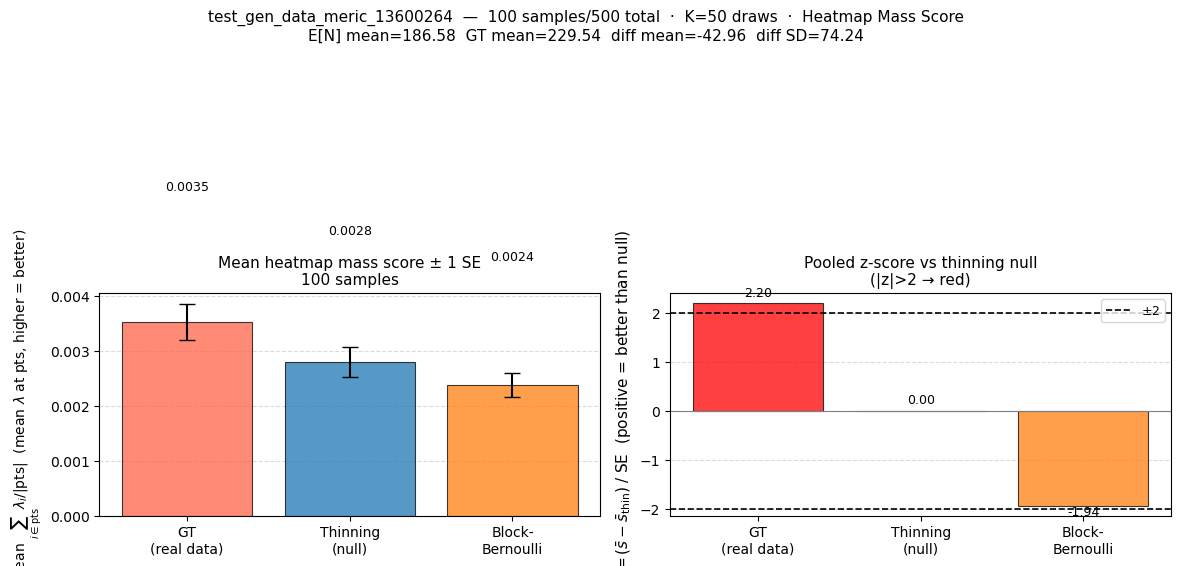


  Model: test_gen_data_meric_1500_13603608_LR_load_model40000  (100 samples, K=50 draws)
  10/100
  20/100
  30/100
  40/100
  50/100
  60/100
  70/100
  80/100
  90/100
  100/100

  Count statistics  (over 100 samples)
  Quantity                            mean      variance          SD
  --------------------------------------------------------------------
  GT point count                   225.510      4883.263      69.880
  Expected count E[N]               57.904      1720.108      41.474
  Diff E[N] − GT count            -167.606      7109.608      84.318

  Mean heatmap mass score  (higher = better)
  Method                    mean score          SE  Δ vs thin / SE
  ----------------------------------------------------------------
  GT (real data)              0.001491    0.000199           -1.08
  Thinning sampler            0.001706    0.000231            0.00
  Block-Bernoulli             0.001537    0.000200           -0.85

  Empirical-null calibration tests  (positive z = 

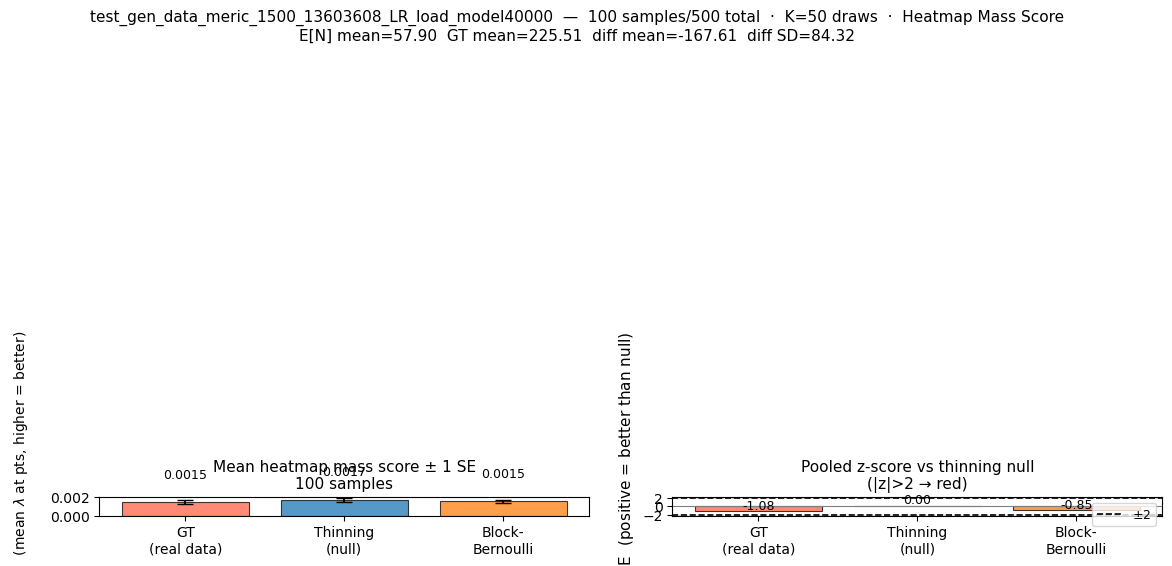


  Model: test_gen_data_meric_1500_13606074  (100 samples, K=50 draws)
  10/100
  20/100
  30/100
  40/100
  50/100
  60/100
  70/100
  80/100
  90/100
  100/100

  Count statistics  (over 100 samples)
  Quantity                            mean      variance          SD
  --------------------------------------------------------------------
  GT point count                   232.700      5210.455      72.183
  Expected count E[N]              117.987      7620.214      87.294
  Diff E[N] − GT count            -114.713     16310.416     127.712

  Mean heatmap mass score  (higher = better)
  Method                    mean score          SE  Δ vs thin / SE
  ----------------------------------------------------------------
  GT (real data)              0.000160    0.000015           -4.82  ***
  Thinning sampler            0.000231    0.000015            0.00
  Block-Bernoulli             0.000231    0.000015            0.05

  Empirical-null calibration tests  (positive z = GT above thinn

/tmp/ipykernel_3712/2934017161.py:172: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


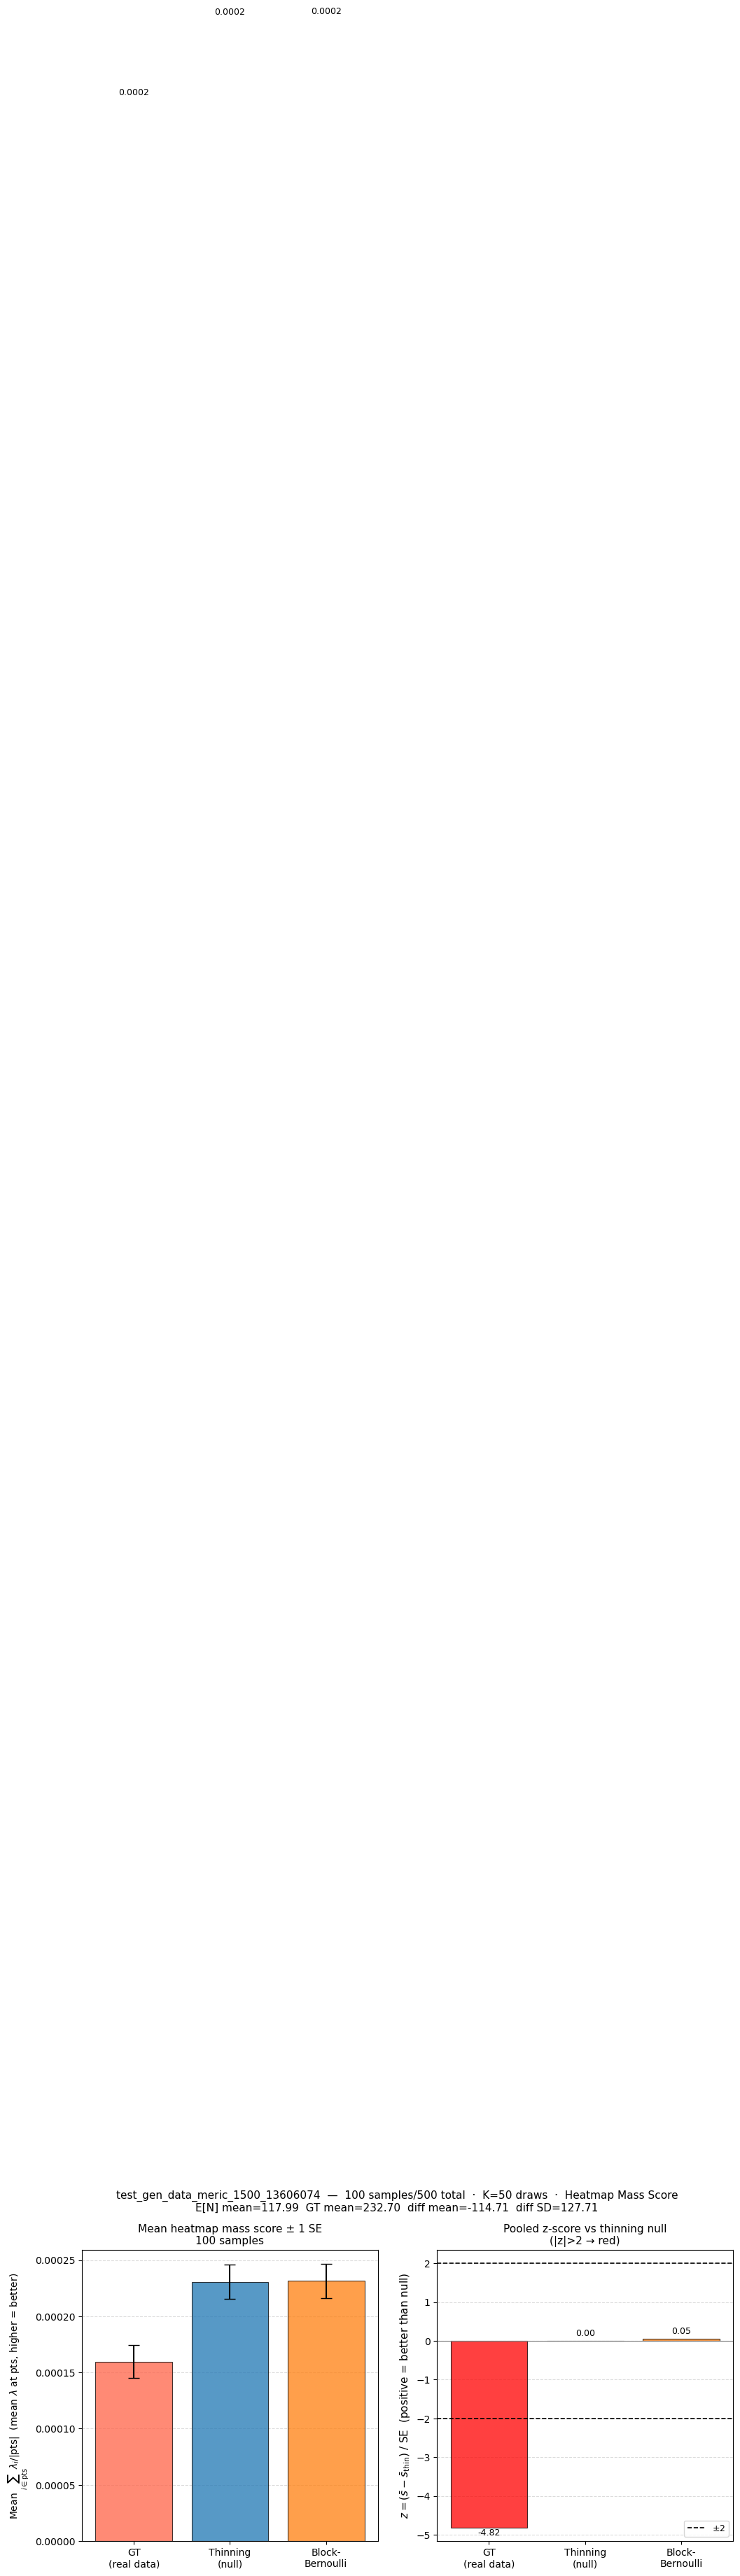

In [ ]:
N_EVAL_POOLED  = 50    # thinning / BB draws per sample  (K)
N_SAMPLES_EVAL = 100   # samples per model  (None = all)


def run_calibration_analysis(model_name: str, h5_dir: str):
    """
    Full empirical-null calibration analysis for one model.

    Primary metric: alignment ratio = mean_lambda(pts) / mean_lambda(all)
      Thinning null gives E[score] = 1 by construction.
      GT > 1 means GT locations have above-average predicted intensity.

    Per-sample null from K thinning draws; z-scored and tested for bias/dispersion.
    """
    _h5_files = sorted(glob.glob(os.path.join(h5_dir, "rank*.h5")))
    assert _h5_files, f"No rank*.h5 files found in {h5_dir}"
    _all  = list_h5_samples(_h5_files)
    _eval = _all if N_SAMPLES_EVAL is None else _all[:N_SAMPLES_EVAL]
    total = len(_eval)
    print(f"\n{'='*70}")
    print(f"  Model: {model_name}  ({total} samples, K={N_EVAL_POOLED} draws)")
    print(f"{'='*70}")

    score_gt_list    = []   # alignment ratio for real GT
    thin_score_list  = []   # K scores per sample (thinning)
    bb_score_list    = []   # K scores per sample (BB)
    gt_count_list    = []   # number of GT points per sample
    exp_count_list   = []   # E[N] = sum(pred_lambda) per sample

    for idx, (_h5_path, _key) in enumerate(_eval):
        if (idx + 1) % max(1, total // 10) == 0 or idx == total - 1:
            print(f"  {idx + 1}/{total}", flush=True)

        _s           = load_h5_sample(_h5_path, _key)
        _pred_lambda = _s["pred_lambda"]
        _gt_support  = _s["gt_support"]
        H_s, W_s     = _pred_lambda.shape

        score_gt_list.append(_projection_scalar(_gt_support, _pred_lambda))
        gt_count_list.append(float(_gt_support.sum()))
        exp_count_list.append(float(_pred_lambda.sum()))

        thin_k = np.empty(N_EVAL_POOLED)
        bb_k   = np.empty(N_EVAL_POOLED)
        for seed in range(N_EVAL_POOLED):
            rng_t = np.random.default_rng(seed)
            pts_t, *_ = sample_ppp_by_thinning(_pred_lambda, rng=rng_t)
            g_t = points_to_binary_grid(pts_t, H_s, W_s)
            thin_k[seed] = _projection_scalar(g_t, _pred_lambda)

            rng_b = np.random.default_rng(seed + 10_000)
            pts_b, _ = sample_points_block_bernoulli(
                _pred_lambda, block_size=8, placement="weighted", rng=rng_b
            )
            g_b = points_to_binary_grid(pts_b, H_s, W_s)
            bb_k[seed] = _projection_scalar(g_b, _pred_lambda)

        thin_score_list.append(thin_k)
        bb_score_list.append(bb_k)

    S            = total
    score_gt_arr = np.array(score_gt_list)
    thin_mean_arr = np.array([v.mean() for v in thin_score_list])
    bb_mean_arr   = np.array([v.mean() for v in bb_score_list])

    gt_count_arr  = np.array(gt_count_list)
    exp_count_arr = np.array(exp_count_list)
    diff_arr      = exp_count_arr - gt_count_arr   # positive = model over-predicts

    def _mean_se(arr):
        m  = arr.mean()
        se = arr.std(ddof=1) / np.sqrt(len(arr))
        return float(m), float(se), float((m - thin_mean_arr.mean()) / (se + EPS))

    M_gt,   SE_gt,   z_pool_gt   = _mean_se(score_gt_arr)
    M_thin, SE_thin, z_pool_thin = _mean_se(thin_mean_arr)
    M_bb,   SE_bb,   z_pool_bb   = _mean_se(bb_mean_arr)

    z_gt_s, z_thin_s, z_bb_s, sigma_s = empirical_null_zscores(
        score_gt_arr, thin_score_list, bb_score_list
    )

    # ── Count statistics ─────────────────────────────────────────────────────
    print(f"\n  Count statistics  (over {S} samples)")
    print(f"  {'Quantity':<28}  {'mean':>10}  {'variance':>12}  {'SD':>10}")
    print(f"  {'-'*68}")
    for label, arr in [
        ("GT point count",         gt_count_arr),
        ("Expected count E[N]",    exp_count_arr),
        ("Diff E[N] − GT count",   diff_arr),
    ]:
        print(f"  {label:<28}  {arr.mean():>10.3f}  {arr.var(ddof=1):>12.3f}  {arr.std(ddof=1):>10.3f}")

    # ── Alignment ratio summary ──────────────────────────────────────────────
    print(f"\n  Mean alignment ratio  (thinning null ≈ 1;  GT > 1 = above-average alignment)")
    print(f"  {'Method':<22}  {'mean ratio':>12}  {'SE':>10}  {'Δ vs thin / SE':>14}")
    print(f"  {'-'*64}")
    for nm, M, SE, zp in [
        ("GT (real data)",   M_gt,   SE_gt,   z_pool_gt),
        ("Thinning sampler", M_thin, SE_thin, z_pool_thin),
        ("Block-Bernoulli",  M_bb,   SE_bb,   z_pool_bb),
    ]:
        sig = "  ***" if abs(zp) > 2 else ""
        print(f"  {nm:<22}  {M:>12.6f}  {SE:>10.6f}  {zp:>14.2f}{sig}")

    print(f"\n  Empirical-null calibration tests  (positive z = GT above thinning null)")
    cal_results = {}
    for nm, z_s in [("GT (real data)",  z_gt_s),
                    ("Thinning (LOO)",  z_thin_s),
                    ("Block-Bernoulli", z_bb_s)]:
        cal_results[nm] = calibration_tests(z_s, nm, verbose=True)
    print("  *** p < 0.05")

    print(f"\n  Per-sample z_s summary")
    print(f"  {'Method':<22}  {'mean |z|':>9}  {'mean z²':>9}  {'SD z':>7}  {'max |z|':>8}")
    print(f"  {'-'*62}")
    for nm, z_s in [("GT (real data)",  z_gt_s),
                    ("Thinning (LOO)",  z_thin_s),
                    ("Block-Bernoulli", z_bb_s)]:
        z = z_s[np.isfinite(z_s)]
        msz = np.dot(z, z) / len(z)
        print(f"  {nm:<22}  {np.abs(z).mean():>9.3f}  {msz:>9.3f}  "
              f"{z.std():>7.3f}  {np.abs(z).max():>8.2f}")

    # ── Figure ───────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
    ax_raw, ax_zp = axes
    base_colors = ["tomato", plt.cm.tab10.colors[0], plt.cm.tab10.colors[1]]
    labels      = ["GT\n(real data)", "Thinning\n(null)", "Block-\nBernoulli"]

    Ms  = [M_gt,   M_thin,  M_bb]
    ses = [SE_gt,  SE_thin, SE_bb]
    bars = ax_raw.bar(labels, Ms, color=base_colors, alpha=0.75,
                      edgecolor="k", linewidth=0.8, yerr=ses, capsize=6,
                      error_kw=dict(ecolor="black", elinewidth=1.5))
    for b, v, s in zip(bars, Ms, ses):
        ax_raw.text(b.get_x() + b.get_width() / 2,
                    b.get_height() + s + 0.002, f"{v:.4f}",
                    ha="center", va="bottom", fontsize=9)
    ax_raw.axhline(1.0, color="grey", linestyle=":", linewidth=1.5, label="null = 1")
    ax_raw.set_ylabel(
        r"Mean $\bar{\lambda}_\mathrm{pts} / \bar{\lambda}$  (alignment ratio;  $>1$ = good)",
        fontsize=10)
    ax_raw.set_title(f"Mean alignment ratio ± 1 SE\n{S} samples  (thinning null ≈ 1)", fontsize=11)
    ax_raw.legend(fontsize=9)
    ax_raw.yaxis.grid(True, linestyle="--", alpha=0.45)
    ax_raw.set_axisbelow(True)

    zps       = [z_pool_gt, z_pool_thin, z_pool_bb]
    zp_colors = ["red" if abs(z) > 2 else c for z, c in zip(zps, base_colors)]
    bars2 = ax_zp.bar(labels, zps, color=zp_colors, alpha=0.75, edgecolor="k", linewidth=0.8)
    ax_zp.axhline( 2.0, color="black", linestyle="--", linewidth=1.2, label=r"$\pm2$")
    ax_zp.axhline(-2.0, color="black", linestyle="--", linewidth=1.2)
    ax_zp.axhline( 0.0, color="grey",  linestyle="-",  linewidth=0.8)
    for b, v in zip(bars2, zps):
        off = 0.08 if v >= 0 else -0.25
        ax_zp.text(b.get_x() + b.get_width() / 2,
                   b.get_height() + off, f"{v:.2f}",
                   ha="center", va="bottom", fontsize=9)
    ax_zp.set_ylabel(r"$z = (\bar{s} - \bar{s}_\mathrm{thin})\;/\;\mathrm{SE}$"
                     "  (positive = above null)", fontsize=11)
    ax_zp.set_title("Pooled z-score vs thinning null\n(|z|>2 → red)", fontsize=11)
    ax_zp.legend(fontsize=9)
    ax_zp.yaxis.grid(True, linestyle="--", alpha=0.45)
    ax_zp.set_axisbelow(True)

    plt.suptitle(
        f"{model_name}  —  {S} samples"
        f"{'/' + str(len(_all)) + ' total' if N_SAMPLES_EVAL is not None else ''}  ·  "
        f"K={N_EVAL_POOLED} draws  ·  Alignment Ratio (null ≈ 1)"
        f"\nE[N] mean={exp_count_arr.mean():.2f}  GT mean={gt_count_arr.mean():.2f}"
        f"  diff mean={diff_arr.mean():+.2f}  diff SD={diff_arr.std(ddof=1):.2f}",
        fontsize=11, y=1.04,
    )
    plt.tight_layout()
    return fig


for _model_name, _h5_dir in H5_DIRS.items():
    if not os.path.isdir(_h5_dir):
        print(f"SKIPPING {_model_name} — directory not found: {_h5_dir}")
        continue
    _fig = run_calibration_analysis(_model_name, _h5_dir)
    plt.show()


test_gen_data_meric_13600264  →  500 samples
  mean score = 0.0038   median = 0.0031   n = 500
test_gen_data_meric_1500_13603608_LR_load_model40000  →  500 samples
  mean score = 0.0016   median = 0.0010   n = 500
test_gen_data_meric_1500_13606074  →  500 samples
  mean score = 0.0002   median = 0.0001   n = 500


/tmp/ipykernel_3712/1707682849.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


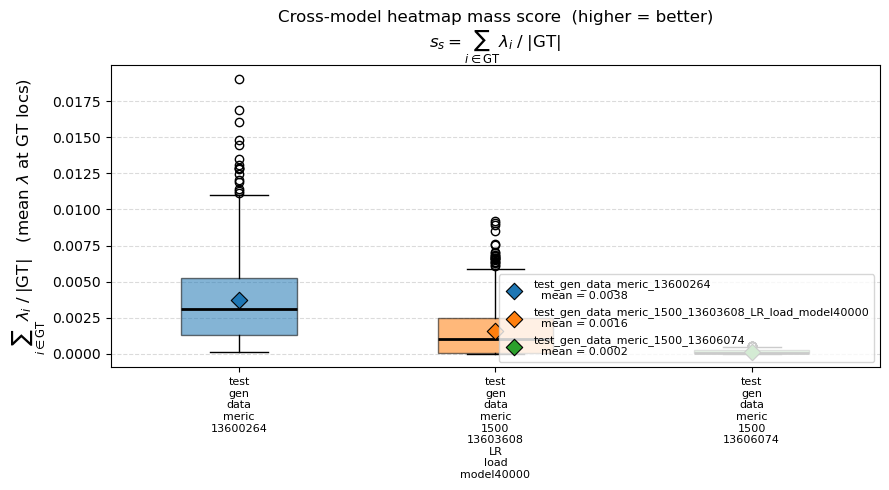

In [ ]:

# ── Cross-model alignment ratio  (thinning null ≈ 1,  GT > 1 = good) ─────────
#
# Per sample s:
#   score_s = mean_lambda(GT locs) / mean_lambda(all)
#           = (sum_{i in GT} lambda_i / |GT|) / (sum_i lambda_i / D)
#
# Independent of point count and scale of lambda.
# Thinning null gives E[score] = 1 by construction.

SAMPLE_N = None   # max samples per model  (None = all)

metric_data = {}   # model_name → ndarray of scores

for _mname, _h5_dir in H5_DIRS.items():
    if not os.path.isdir(_h5_dir):
        print(f"SKIPPING {_mname} — directory not found")
        continue

    _h5_files = sorted(glob.glob(os.path.join(_h5_dir, "rank*.h5")))
    _all_s    = list_h5_samples(_h5_files)
    _eval_s   = _all_s if SAMPLE_N is None else _all_s[:SAMPLE_N]
    print(f"{_mname}  →  {len(_eval_s)} samples", flush=True)

    _scores = []
    for _h5_path, _key in _eval_s:
        _s = load_h5_sample(_h5_path, _key)
        _scores.append(_projection_scalar(_s["gt_support"], _s["pred_lambda"]))

    arr = np.array(_scores)
    metric_data[_mname] = arr
    print(f"  mean ratio = {arr.mean():.4f}   median = {np.median(arr):.4f}"
          f"   n = {len(arr)}")

# ── Plot ──────────────────────────────────────────────────────────────────────
_mnames = list(metric_data.keys())
_vals   = [metric_data[m] for m in _mnames]
_colors = [plt.cm.tab10.colors[i % 10] for i in range(len(_mnames))]

fig, ax = plt.subplots(figsize=(max(6, 3 * len(_mnames)), 5))

bp = ax.boxplot(
    _vals, labels=_mnames, patch_artist=True,
    widths=0.45, medianprops=dict(color="black", linewidth=2),
)
for patch, color in zip(bp["boxes"], _colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.55)

for i, (vals, color, name) in enumerate(zip(_vals, _colors, _mnames), start=1):
    _mean = vals.mean()
    ax.scatter(i, _mean, marker="D", s=70, color=color,
               edgecolors="black", linewidths=0.8, zorder=5,
               label=f"{name}\n  mean = {_mean:.4f}")

ax.axhline(1.0, color="grey", linestyle=":", linewidth=1.5, label="thinning null = 1")
ax.set_ylabel(
    r"$\bar{\lambda}_\mathrm{GT} / \bar{\lambda}$   (alignment ratio;  $>1$ = good)", fontsize=12)
ax.set_title(
    "Cross-model alignment ratio  (thinning null ≈ 1,  GT > 1 = above-average)\n"
    r"$s_s = \bar{\lambda}_\mathrm{GT} / \bar{\lambda}$",
    fontsize=12,
)
ax.legend(fontsize=8, loc="lower right")
ax.yaxis.grid(True, linestyle="--", alpha=0.45)
ax.set_axisbelow(True)
ax.set_xticklabels([m.replace("_", "\n") for m in _mnames], fontsize=8)

plt.tight_layout()
plt.show()


In [83]:
## Appendix · Synthetic Demo of the Heatmap Mass Score

Three controlled scenarios show that the metric correctly separates alignment from misalignment
**regardless of how many points are used**:

| Scenario | Expected score |
|---|---|
| **Aligned** — points placed exactly at the heatmap peak | ≈ 1 |
| **Diffuse** — flat heatmap, tight GT cluster | moderate (heatmap mass is spread out) |
| **Shifted** — points in a region where the model predicts nothing | ≈ 0 |


SyntaxError: invalid character '—' (U+2014) (2378510977.py, line 8)

In [ ]:

# ── Synthetic demo ────────────────────────────────────────────────────────────
#
# Demonstrates that  score = <x, lam> / ||lam||_1
# correctly distinguishes aligned from misaligned detections
# regardless of image size D or number of points.


def visualize_mass_score(
    x_gt: np.ndarray,
    lam: np.ndarray,
    score: float,
    title: str = "",
    save_path: str | None = None,
) -> plt.Figure:
    """3-panel visualisation: GT map | heatmap | pointwise contribution."""
    x_gt = np.asarray(x_gt, dtype=np.float64)
    lam  = np.asarray(lam,  dtype=np.float64)

    # Per-pixel contribution to the numerator: x_i * lambda_i
    contribution = x_gt * lam

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    im0 = axes[0].imshow(x_gt, cmap="Greys_r", vmin=0, vmax=1)
    axes[0].set_title("x_gt  (binary GT)", fontsize=10)
    plt.colorbar(im0, ax=axes[0], fraction=0.046)
    axes[0].axis("off")

    im1 = axes[1].imshow(lam, cmap="hot")
    axes[1].set_title("λ  (heatmap)", fontsize=10)
    plt.colorbar(im1, ax=axes[1], fraction=0.046)
    axes[1].axis("off")

    im2 = axes[2].imshow(contribution, cmap="hot")
    axes[2].set_title(r"$x_i \cdot \lambda_i$  (numerator contribution)", fontsize=10)
    plt.colorbar(im2, ax=axes[2], fraction=0.046)
    axes[2].axis("off")

    score_str = f"{score:.4f}" if not np.isnan(score) else "nan"
    fig.suptitle(
        f"{title}   |   mass score = {score_str}"
        f"   (= {contribution.sum():.4f} / {lam.sum():.4f})",
        fontsize=12, y=1.02,
    )
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight", dpi=150)
    return fig


def demo_synthetic(H: int = 64, W: int = 96, rng_seed: int = 0):
    """
    Three synthetic scenarios for the heatmap mass score.
    Uses different point counts to show score is count-independent.
    """
    rng = np.random.default_rng(rng_seed)
    yy, xx = np.mgrid[0:H, 0:W]

    def gauss2d(cy, cx, sy, sx):
        return np.exp(-0.5 * (((yy - cy) / sy) ** 2 + ((xx - cx) / sx) ** 2))

    def place_pts(cy, cx, sy, sx, n):
        ys = np.clip(rng.normal(cy, sy, n).astype(int), 0, H - 1)
        xs = np.clip(rng.normal(cx, sx, n).astype(int), 0, W - 1)
        g  = np.zeros((H, W), dtype=np.float64)
        g[ys, xs] = 1.0
        return g

    lam_sharp   = gauss2d(H * 0.4, W * 0.6, H * 0.08, W * 0.08)
    lam_diffuse = gauss2d(H * 0.5, W * 0.5, H * 0.30, W * 0.30)

    scenarios = {
        "A — Aligned  (5 pts at peak)": (
            lam_sharp,
            place_pts(H * 0.4, W * 0.6, H * 0.05, W * 0.05, n=5),
        ),
        "A — Aligned  (50 pts at peak)": (
            lam_sharp,
            place_pts(H * 0.4, W * 0.6, H * 0.05, W * 0.05, n=50),
        ),
        "B — Diffuse heatmap  (20 pts at centre)": (
            lam_diffuse,
            place_pts(H * 0.5, W * 0.5, H * 0.04, W * 0.04, n=20),
        ),
        "C — Shifted  (20 pts where λ ≈ 0)": (
            lam_sharp,
            place_pts(H * 0.5, W * 0.15, H * 0.05, W * 0.05, n=20),
        ),
    }

    for name, (lam, x_gt) in scenarios.items():
        score = heatmap_mass_score(x_gt, lam)
        visualize_mass_score(x_gt, lam, score, title=name)
        plt.show()
        n_pts = int(x_gt.sum())
        print(f"{name.split(chr(10))[0]}:  N={n_pts}  score = {score:.4f}\n")


demo_synthetic()
